# 6BUIS017W CRM & CM Coursework (CWK1) – Uvindu Sandasara – 20221297 / w2087738
**Market Analysis and Stock Segmentation Using RFM**


In [63]:
# Step 1: install yfinance, lxml and seaborn (quietly)
%pip -q install yfinance lxml seaborn

In [64]:
# Setup – import libraries, create the output folders and fix every setting used in the coursework
# Step 1: import the libraries
import json, platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
try:
    import yfinance as yf
except ImportError:
    yf = None

# Step 2: create the output folders
OUT = Path("cwk1_outputs"); DAILY = OUT / "daily_shares"; FIG = OUT / "figures"
DAILY.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# Step 3: fix the settings from the brief
START, END = "2021-01-01", "2025-01-01"     # END is exclusive -> last day 31 Dec 2024
BENCHMARK = "^GSPC"
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
BASELINE, WINDOW = 20, 60                    # RFM: previous 20 sessions, latest 60 sessions
SEED, N_INIT = 42, 50                        # K-means seed and number of starts

# Step 4: use the saved data snapshot if it is already there
USE_SAVED = (OUT / "download_log.csv").exists() and (OUT / "benchmark.csv").exists()

# Step 5: record the package versions (a deliverable) and print them
versions = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "seaborn": sns.__version__,
            "yfinance": getattr(yf, "__version__", "not installed"),
            "data": "saved snapshot" if USE_SAVED else "fresh download"}
(OUT / "package_versions.json").write_text(json.dumps(versions, indent=2))
print(json.dumps(versions, indent=1))

{
 "python": "3.13.18",
 "pandas": "2.2.3",
 "numpy": "2.4.6",
 "scipy": "1.16.3",
 "scikit-learn": "1.6.1",
 "seaborn": "0.13.2",
 "yfinance": "0.2.66",
 "data": "saved snapshot"
}


## Task 1 – Data preparation and feature engineering
### 1.1 Ticker selection and data acquisition


In [65]:
# Task 1.1 – Part 1: get the S&P 500 ticker list from Wikipedia (pandas) and record when it was retrieved
# Step 1: load the saved list, or read it from Wikipedia and save it with its retrieval time
if USE_SAVED:
    constituents = pd.read_csv(OUT / "constituents_snapshot.csv")      # saved list from the first run
    retrieved = constituents["RetrievedUTC"].iloc[0]
else:
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0 Safari/537.36"}
    constituents = pd.read_html(WIKI_URL, attrs={"id": "constituents"}, storage_options=headers)[0]
    retrieved = datetime.now(timezone.utc).isoformat(timespec="seconds")        # retrieval time
    constituents["Symbol"] = constituents["Symbol"].str.strip()
    constituents["YahooTicker"] = constituents["Symbol"].str.replace(".", "-", regex=False)   # BRK.B -> BRK-B
    constituents["RetrievedUTC"] = retrieved
    constituents.to_csv(OUT / "constituents_snapshot.csv", index=False)

# Step 2: make the ticker list and a ticker -> sector lookup
tickers = constituents["YahooTicker"].drop_duplicates().tolist()           # unique Yahoo tickers
sector = constituents.drop_duplicates("YahooTicker").set_index("YahooTicker")["GICS Sector"]   # ticker -> GICS sector
# Step 3: show how many tickers and sectors were found
print(f"Constituent list read at {retrieved} (UTC): {len(tickers)} tickers in {sector.nunique()} sectors")
constituents[["Symbol", "YahooTicker", "Security", "GICS Sector"]].head()

Constituent list read at 2026-11-23T17:43:06+00:00 (UTC): 503 tickers in 11 sectors


,Symbol,YahooTicker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


In [66]:
# Task 1.1 – Part 2: download daily prices, adjusted prices, volume, dividends and splits for ^GSPC and every share
# Step 1: one yfinance call per ticker for the whole study period
def download_one(ticker):
    # raw Close and Adj Close are both kept (auto_adjust=False); dividend and split events are fetched too (actions=True)
    return yf.download(ticker, start=START, end=END, interval="1d", auto_adjust=False, actions=True,
                       keepna=True, multi_level_index=False, progress=False, threads=False)

# Step 2: reuse the saved download log, or download every ticker and log the result
if USE_SAVED:
    download_log = pd.read_csv(OUT / "download_log.csv")
else:
    log = []
    for ticker in [BENCHMARK, *tickers]:                     # benchmark first, then every share
        row = {"ticker": ticker}
        try:
            df = download_one(ticker)
            if df is None or df.empty or df["Close"].isna().all():
                row.update(status="No closing prices returned", rows=0)    # e.g. a share listed after 2024
            else:
                df.to_csv(OUT / "benchmark.csv" if ticker == BENCHMARK else DAILY / f"{ticker}_daily.csv", index_label="Date")
                row.update(status="Saved for validation", rows=len(df), first_date=df.index.min().date(), last_date=df.index.max().date())
        except Exception as exc:
            row.update(status="Download error", rows=0, detail=str(exc))   # one bad ticker never stops the loop
        log.append(row)
    download_log = pd.DataFrame(log)
    download_log.to_csv(OUT / "download_log.csv", index=False)
    (OUT / "retrieval_metadata.txt").write_text(
        f"Constituents: {WIKI_URL}\nRetrieved (UTC): {retrieved}\nMarket data: yfinance {yf.__version__}\n"
        f"Period: {START} to {END} (end exclusive)\nBenchmark: {BENCHMARK}\n")

# Step 3: show how many downloads worked and which failed
print(download_log["status"].value_counts().to_string())
download_log.loc[download_log["status"].ne("Saved for validation"), ["ticker", "status"]]

status
Saved for validation          499
No closing prices returned      5


,ticker,status
193,FDXF,No closing prices returned
234,HONA,No closing prices returned
380,Q,No closing prices returned
403,SNDK,No closing prices returned
479,VYLR,No closing prices returned


### 1.2 Data validation and alignment


In [67]:
# Task 1.2 – Part 1: load the benchmark; its trading days become the reference calendar
# Step 1: a helper that reads one saved CSV with dates as the index
def read_daily(path):
    return pd.read_csv(path, parse_dates=["Date"]).set_index("Date").sort_index()

# Step 2: load ^GSPC and use its trading days as the calendar
benchmark = read_daily(OUT / "benchmark.csv")
sessions = benchmark.index                              # the reference trading calendar
# Step 3: check the benchmark has no duplicate dates and positive prices
assert not sessions.has_duplicates and (benchmark["Adj Close"] > 0).all()
print(f"^GSPC: {len(sessions)} sessions from {sessions.min().date()} to {sessions.max().date()}, no duplicate dates")

^GSPC: 1005 sessions from 2021-01-04 to 2024-12-31, no duplicate dates


In [68]:
# Task 1.2 – Part 2: validate every share and record why any share is excluded
# Step 1: loop over every downloaded share
valid_shares, raw_shares, records = {}, {}, []
for row in download_log.itertuples(index=False):
    if row.ticker == BENCHMARK:
        continue
    rec = {"ticker": row.ticker, "sector": sector.get(row.ticker), "decision": "Excluded"}   # excluded unless every check passes
    if row.status != "Saved for validation":
        rec["reason"] = row.status; records.append(rec); continue

    # Step 2: load the share and run the six checks
    df = read_daily(DAILY / f"{row.ticker}_daily.csv")
    data = df[["Close", "Adj Close", "Volume"]].apply(pd.to_numeric, errors="coerce")
    # each check counts the rows that break a rule (0 = passed)
    checks = {"duplicate_dates": int(df.index.duplicated().sum()),
              "missing_market_sessions": len(sessions.difference(df.index)),     # unequal history
              "extra_dates": len(df.index.difference(sessions)),
              "missing_price_rows": int(data[["Close", "Adj Close"]].isna().any(axis=1).sum()),
              "nonpositive_price_rows": int(data[["Close", "Adj Close"]].le(0).any(axis=1).sum()),
              "bad_volume_rows": int((data["Volume"].isna() | data["Volume"].lt(0)).sum())}
    zero_days = int(data["Volume"].eq(0).sum())                       # many zero-volume days = stale quotes
    rec.update(checks, zero_volume_days=zero_days)

    # Step 3: list the failed checks; keep the share only if none failed
    problems = [f"{k}={v}" for k, v in checks.items() if v]
    if zero_days >= 10:
        problems.append(f"stale quotes: zero_volume_days={zero_days}")
    if problems:
        rec["reason"] = ", ".join(problems)
    else:
        rec.update(decision="Included", reason="Passed daily validation")
        valid_shares[row.ticker] = data.reindex(sessions)           # Close, Adj Close, Volume on the common calendar
        raw_shares[row.ticker] = df.reindex(sessions)               # full data incl. Dividends / Stock Splits
    records.append(rec)

# Step 4: save the log and show the excluded shares with their reasons
validation_log = pd.DataFrame(records)
validation_log.to_csv(OUT / "validation_log.csv", index=False)
print(validation_log["decision"].value_counts().to_string())
validation_log.loc[validation_log["decision"].eq("Excluded"), ["ticker", "sector", "reason"]]

decision
Included    486
Excluded     17


,ticker,sector,reason
40,APP,Communication Services,missing_market_sessions=70
116,COIN,Financials,missing_market_sessions=69
123,CEG,Utilities,missing_market_sessions=263
181,EXE,Energy,missing_market_sessions=26
192,FDXF,Industrials,No closing prices returned
193,FERG,Industrials,stale quotes: zero_volume_days=27
210,GEHC,Health Care,missing_market_sessions=492
211,GEV,Industrials,missing_market_sessions=812
233,HONA,Industrials,No closing prices returned
379,Q,Information Technology,No closing prices returned


#### 1.2 Corporate actions


In [69]:
# Task 1.2 – Part 3: corporate-action checks (splits, dividends, very large one-day moves)
# Step 1: loop over every valid share
rows = []
for ticker, df in raw_shares.items():
    close, adj, vol = df["Close"], df["Adj Close"], df["Volume"]
    splits, divs = df["Stock Splits"].fillna(0), df["Dividends"].fillna(0)

    # Step 2: test 1 – on each split day, compare the Close move with the split ratio
    for day in splits.index[splits > 0]:                       # test 1: split days
        p = close.index.get_loc(day)
        ratio, move = splits[day], close.iloc[p] / close.iloc[p - 1]
        genuine = abs(np.log(ratio)) >= np.log(1.25)             # tiny ratios are spin-off adjustments (e.g. ILMN)
        rows.append({"ticker": ticker, "date": day.date(), "check": "split", "split_ratio": ratio,
                     "kind": "split" if genuine else "spin-off adjustment",
                     "close_move_pct": round((move - 1) * 100, 1),
                     "volume_5d_after_vs_before": round(vol.iloc[p:p + 5].mean() / vol.iloc[p - 5:p].mean(), 2),
                     "problem": bool(genuine and abs(np.log(move)) > 0.5 * abs(np.log(ratio)))})

    # Step 3: test 2 – Adj Close / Close may only change around dividend days
    r = adj / close                                             # test 2: dividend adjustment
    div_day = divs > 0
    near_div = div_day | div_day.shift(1, fill_value=False) | div_day.shift(-1, fill_value=False)
    odd_moves = int(((r.pct_change(fill_method=None).abs() > 0.01) & ~near_div).sum())
    rows.append({"ticker": ticker, "check": "adj/close ratio", "problem": bool(r.min() <= 0 or r.max() > 1.0001 or odd_moves)})

    # Step 4: test 3 – very large one-day moves must also appear in Adj Close
    c_ret, a_ret = close.pct_change(fill_method=None), adj.pct_change(fill_method=None)   # test 3: big moves
    for day in c_ret.index[(c_ret < -0.40) | (c_ret > 0.80)]:
        rows.append({"ticker": ticker, "date": day.date(), "check": "large move", "close_move_pct": round(c_ret[day] * 100, 1),
                     "problem": bool(abs(c_ret[day] - a_ret[day]) > 0.02)})

# Step 5: save all tests and count the problems
corporate_actions = pd.DataFrame(rows)
corporate_actions.to_csv(OUT / "corporate_action_checks.csv", index=False)
display(corporate_actions.groupby("check")["problem"].agg(tests="count", problems="sum"))

# Step 6: build the table of genuine splits and summarise it
splits_table = corporate_actions.query("check == 'split' and kind == 'split'")[
    ["ticker", "date", "split_ratio", "close_move_pct", "volume_5d_after_vs_before"]].sort_values("date").reset_index(drop=True)
biggest = splits_table.loc[splits_table["close_move_pct"].abs().idxmax()]
print(f"{len(splits_table)} genuine splits tested (+{(corporate_actions['kind'] == 'spin-off adjustment').sum()} spin-off adjustments). "
      f"Biggest Close move on a split day: {biggest['close_move_pct']:+.1f}% ({biggest['ticker']}, {biggest['date']}); "
      f"5-day volume after/before ranges {splits_table['volume_5d_after_vs_before'].min():.2f}–{splits_table['volume_5d_after_vs_before'].max():.2f}. "
      "Unadjusted data would show moves close to the split ratio, so prices and volumes are split-adjusted.")
splits_table

,tests,problems
check,,
adj/close ratio,486,0
large move,3,0
split,61,0


49 genuine splits tested (+12 spin-off adjustments). Biggest Close move on a split day: +7.7% (T, 2022-04-11); 5-day volume after/before ranges 0.42–2.37. Unadjusted data would show moves close to the split ratio, so prices and volumes are split-adjusted.


,ticker,date,split_ratio,close_move_pct,volume_5d_after_vs_before
0,APH,2021-03-05,2.000,2.5,0.93
1,SHW,2021-04-01,3.000,1.5,1.17
2,CSGP,2021-06-28,10.000,-3.8,0.97
3,CSX,2021-06-29,3.000,-0.7,1.19
4,NVDA,2021-07-20,4.000,-0.9,0.58
5,GE,2021-08-02,0.125,-2.9,1.63
6,RJF,2021-09-22,1.500,1.2,1.13
7,ISRG,2021-10-05,3.000,2.0,0.83
8,MCHP,2021-10-13,2.000,-0.3,0.87
9,DELL,2021-11-02,1.973,-3.4,1.32


#### 1.2 Weekly alignment


In [70]:
# Task 1.2 – Part 4: Friday weekly prices and aligned weekly returns for ^GSPC and all shares
# Step 1: one table of daily Adj Close (^GSPC first, then every share)
daily_adj = pd.DataFrame({BENCHMARK: benchmark["Adj Close"], **{t: d["Adj Close"] for t, d in valid_shares.items()}})
# Step 2: keep complete Friday weeks and the last price of each week
complete_weeks = pd.date_range("2021-01-08", "2024-12-27", freq="W-FRI")   # complete Friday weeks only
weekly_prices = daily_adj.resample("W-FRI").last().reindex(complete_weeks)  # last available price of each week
# Step 3: weekly return = this week / last week - 1, then save
weekly_returns = (weekly_prices / weekly_prices.shift(1) - 1).iloc[1:]      # P(t) / P(t-1) - 1
weekly_returns.index.name = "WeekEnding"
weekly_returns.to_csv(OUT / "weekly_returns_aligned.csv")

# Step 4: check: all weeks are Fridays and nothing is missing
assert (weekly_returns.index.dayofweek == 4).all() and weekly_returns.notna().all().all()   # all Fridays, nothing missing
print(f"{len(weekly_returns)} weekly returns per series ({weekly_returns.index[0].date()} to {weekly_returns.index[-1].date()}), none missing")
weekly_returns.iloc[:3, :5]

207 weekly returns per series (2021-01-15 to 2024-12-27), none missing


,^GSPC,MMM,AOS,ABT,ABBV
WeekEnding,,,,,
2021-01-15,-0.014754,-0.006422,0.011930,0.001240,0.042348
2021-01-22,0.019431,0.021081,0.016365,0.013837,0.003076
2021-01-29,-0.033120,0.039162,-0.055285,0.095268,-0.075591


### 1.3 Weekly return and weekly beta
#### 1.3.1 Mean weekly return


In [71]:
# Task 1.3.1 – mean weekly return (arithmetic mean of the 207 weekly returns)
# Step 1: split the table into the market column and the share columns
market = weekly_returns[BENCHMARK]
shares = weekly_returns.drop(columns=BENCHMARK)                      # one column per share

# Step 2: mean weekly return and the number of aligned weeks for each share
risk_return = pd.DataFrame({"mean_weekly_return": shares.mean(),    # arithmetic mean
                            "aligned_weeks": shares.notna().sum()})   # aligned weekly observations
risk_return.index.name = "ticker"
# Step 3: show the aligned weeks and four example shares
print("Aligned weekly observations:", risk_return["aligned_weeks"].unique())
risk_return.loc[["AAPL", "MSFT", "JNJ", "NVDA"]].assign(mean_pct=lambda d: d["mean_weekly_return"] * 100).round(4)

Aligned weekly observations: [207]


,mean_weekly_return,aligned_weeks,mean_pct
ticker,,,
AAPL,0.0039,207,0.3930
MSFT,0.0040,207,0.3982
JNJ,0.0003,207,0.0292
NVDA,0.0136,207,1.3624


#### 1.3.2 Weekly beta
β = Cov(share, ^GSPC) / Var(^GSPC) over the full period (sample statistics, n − 1).

In [72]:
# Task 1.3.2 – weekly beta = Cov(share, ^GSPC) / Var(^GSPC)
# Step 1: beta = covariance with the market / variance of the market
risk_return["weekly_beta"] = shares.apply(lambda s: s.cov(market)) / market.var()
# Step 2: two extra descriptive columns
risk_return["weekly_volatility"] = shares.std()                      # extra: weekly standard deviation
risk_return["corr_with_market"] = shares.corrwith(market)           # extra: correlation with ^GSPC
# Step 3: summarise beta and show four example shares
print(risk_return["weekly_beta"].describe().round(3).to_string())
risk_return.loc[["AAPL", "MSFT", "JNJ", "NVDA"], ["weekly_beta", "weekly_volatility", "corr_with_market"]].round(4)

count    486.000
mean       0.974
std        0.407
min        0.055
25%        0.667
50%        0.951
75%        1.180
max        3.779


,weekly_beta,weekly_volatility,corr_with_market
ticker,,,
AAPL,1.1748,0.0355,0.7333
MSFT,1.1286,0.0338,0.7418
JNJ,0.3051,0.0214,0.3168
NVDA,2.1260,0.0682,0.6914


#### 1.3.3 Independent checks


In [73]:
# Task 1.3.3 – independent checks of beta and of the mean weekly return
# Step 1: re-estimate beta as a regression slope
risk_return["beta_ols_check"] = [np.polyfit(market, shares[t], 1)[0] for t in risk_return.index]   # regression slope
# Step 2: recompute the mean return straight from prices, and the compound (geometric) mean
p = weekly_prices.drop(columns=BENCHMARK)                            # recompute returns straight from prices
risk_return["mean_from_prices"] = (p.to_numpy()[1:] / p.to_numpy()[:-1] - 1).mean(axis=0)
risk_return["geometric_mean_weekly_return"] = (1 + shares).prod() ** (1 / len(shares)) - 1   # compound weekly growth

# Step 3: both checks must agree for every share
assert np.allclose(risk_return["weekly_beta"], risk_return["beta_ols_check"])
assert np.allclose(risk_return["mean_weekly_return"], risk_return["mean_from_prices"])
print("Both independent checks agree for all", len(risk_return), "shares")
risk_return.loc[["AAPL"], ["weekly_beta", "beta_ols_check", "mean_weekly_return", "mean_from_prices", "geometric_mean_weekly_return"]].round(6)

Both independent checks agree for all 486 shares


,weekly_beta,beta_ols_check,mean_weekly_return,mean_from_prices,geometric_mean_weekly_return
ticker,,,,,
AAPL,1.174836,1.174836,0.00393,0.00393,0.003304


#### 1.3.4 Estimation limits


In [74]:
# Task 1.3.4 – estimation limits: how precise and how stable beta is
# Step 1: standard error and R-squared of beta
n = len(shares)
first = shares.index <= "2022-12-30"                               # 2021-22 vs 2023-24
rho = risk_return["corr_with_market"]
risk_return["beta_std_error"] = np.sqrt((1 - rho**2) / (n - 2)) * shares.std() / market.std()   # standard error of beta
risk_return["r_squared"] = rho**2                                     # share of weekly movement explained by the market
# Step 2: beta in each half of the period (stability)
risk_return["beta_2021_22"] = shares[first].apply(lambda s: s.cov(market[first])) / market[first].var()
risk_return["beta_2023_24"] = shares[~first].apply(lambda s: s.cov(market[~first])) / market[~first].var()
# Step 3: save all risk-return features
risk_return.reset_index().to_csv(OUT / "risk_return_features.csv", index=False)

# Step 4: one summary of how precise beta is
beta_estimation = pd.Series({
    "median beta standard error": risk_return["beta_std_error"].median(),
    "median 95% interval width": (2 * 1.97 * risk_return["beta_std_error"]).median(),
    "median R-squared": risk_return["r_squared"].median(),
    "corr(beta 2021-22, beta 2023-24)": risk_return["beta_2021_22"].corr(risk_return["beta_2023_24"]),
    "median |beta change| between halves": (risk_return["beta_2023_24"] - risk_return["beta_2021_22"]).abs().median(),
    "median arithmetic - geometric mean (pp/week)": ((risk_return["mean_weekly_return"] - risk_return["geometric_mean_weekly_return"]) * 100).median()})
beta_estimation.to_csv(OUT / "beta_estimation_summary.csv")

# Step 5: how many shares switch side of beta = 1 between 2021-22 and 2023-24?
switch = (risk_return["beta_2021_22"] > 1) != (risk_return["beta_2023_24"] > 1)
print("Shares whose beta crosses 1 between the two halves:", int(switch.sum()))
beta_estimation.round(3)

Shares whose beta crosses 1 between the two halves: 108


,0
median beta standard error,0.101
median 95% interval width,0.397
median R-squared,0.284
"corr(beta 2021-22, beta 2023-24)",0.783
median |beta change| between halves,0.214
median arithmetic - geometric mean (pp/week),0.074


### 1.4 Adapted RFM


In [75]:
# Task 1.4 – observation date, 60-session window and the daily high-volume events
# Step 1: observation date and the 60-session window
observation_date = sessions[-1]                                       # last common completed trading day (31 Dec 2024)
recent = sessions[-WINDOW:]                                          # the latest 60 sessions

# Step 2: daily Volume and Close tables (rows = days, columns = shares)
volume = pd.DataFrame({t: d["Volume"] for t, d in valid_shares.items()})     # rows = trading days, columns = shares
close = pd.DataFrame({t: d["Close"] for t, d in valid_shares.items()})
# Step 3: the 20-session baseline, the 2x threshold and the event flags
prior_20_mean = volume.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()   # mean of the 20 PREVIOUS sessions
threshold = 2 * prior_20_mean                                        # event threshold = 2 x baseline
event = volume.gt(threshold) & threshold.notna()                     # True = high-volume event day (strictly greater)
# Step 4: daily traded value for Monetary
traded_value = close * volume                                        # daily Close x Volume in USD

# Step 5: check the window has a full baseline and print the dates
assert threshold.loc[recent].notna().all().all()          # full baseline on every window day
print(f"Observation date {observation_date.date()} | window {recent[0].date()} to {recent[-1].date()} ({len(recent)} sessions)")

Observation date 2024-12-31 | window 2024-10-07 to 2024-12-31 (60 sessions)


#### 1.4.1 Recency

In [76]:
# Task 1.4.1 – Recency (R): calendar days since the latest high-volume event
# Step 1: find each share's latest event
last_event = event.apply(lambda col: col.index[col].max() if col.any() else pd.NaT)
# Step 2: count calendar days to the observation date
recency = (observation_date - last_event).dt.days                    # calendar days; missing if there was no event
# Step 3: show how many shares had no event and summarise R
print("Shares without any event:", int(recency.isna().sum()))
recency.describe().round(2).to_frame("R (days)")

Shares without any event: 0


,R (days)
count,486.00
mean,20.41
std,21.34
min,4.00
25%,11.00
50%,11.00
75%,14.75
max,222.00


#### 1.4.2 Frequency

In [77]:
# Task 1.4.2 – Frequency (F): number of high-volume days in the latest 60 sessions
# Step 1: count event days inside the 60-session window and show how F is spread
frequency = event.loc[recent].sum().astype(int)
frequency.value_counts().sort_index().to_frame("number of shares")

,number of shares
0,10
1,42
2,130
3,149
4,94
5,45
6,11
7,3
8,2


#### 1.4.3 Monetary

In [78]:
# Task 1.4.3 – Monetary (M): sum of Close x Volume over the latest 60 sessions, then one RFM table
# Step 1: add up Close x Volume over the window
monetary = traded_value.loc[recent].sum()

# Step 2: put R, F and M in one table and save it
rfm = pd.DataFrame({"last_high_volume_date": last_event.dt.date, "recency_days": recency.astype("Int64"),
                    "frequency_days": frequency, "monetary_usd": monetary, "events_in_history": event.sum()})
# Step 3: mark shares without any event as not eligible
rfm["rfm_status"] = np.where(rfm["recency_days"].notna(), "Eligible", "Excluded: no qualifying event")
rfm.index.name = "ticker"
rfm.to_csv(OUT / "rfm_features.csv")

# Step 4: save the daily event flags
flags = pd.concat({"Volume": volume, "prior_20_mean": prior_20_mean, "threshold": threshold, "event": event}, axis=1)
flags.stack(level=1, future_stack=True).swaplevel().sort_index().to_csv(OUT / "rfm_event_flags_daily.csv.gz", compression="gzip")
# Step 5: summarise R, F and M
rfm[["recency_days", "frequency_days", "monetary_usd"]].astype(float).describe().round(2)

,recency_days,frequency_days,monetary_usd
count,486.00,486.00,4.860000e+02
mean,20.41,2.99,3.940419e+10
std,21.34,1.33,1.291388e+11
min,4.00,0.00,1.297483e+09
25%,11.00,2.00,1.019517e+10
50%,11.00,3.00,1.668382e+10
75%,14.75,4.00,3.227689e+10
max,222.00,8.00,1.847697e+12


#### 1.4 Rule checks

In [79]:
# Task 1.4 – checks that the RFM rules were applied correctly (thresholds, window, R and F agree)
# Step 1: rebuild one threshold by hand
i = 500                                                        # any day after the baseline
hand = 2 * volume.iloc[i - BASELINE:i].mean()                 # days i-20 ... i-1, day i excluded
# Step 2: check every RFM rule and stop if any fails
inside = pd.to_datetime(rfm["last_high_volume_date"]) >= recent[0]
rule_checks = pd.Series({
    "threshold = 2 x mean of the 20 previous sessions": bool(np.allclose(hand, threshold.iloc[i])),
    "no threshold during the first 20 sessions": bool(threshold.iloc[:BASELINE].isna().all().all()),
    "window has a full 20-session baseline before it": sessions.get_loc(recent[0]) >= BASELINE,
    "R >= 0 for every share": bool((rfm["recency_days"] >= 0).all()),
    "F > 0 exactly when the latest event is inside the window": bool(((rfm["frequency_days"] > 0) == inside).all()),
    "M > 0 for every share": bool((rfm["monetary_usd"] > 0).all())})
assert rule_checks.all()
display(rule_checks.to_frame("ok"))

# Step 3: edge cases and market-wide event days
per_day = event.loc[recent].sum(axis=1)
per_day.to_csv(OUT / "events_per_day_in_window.csv", header=["shares_with_event"])
print("R = 0 (event on the observation date):", int((rfm["recency_days"] == 0).sum()),
      "| F = 0:", int((rfm["frequency_days"] == 0).sum()))
print("Days with the most events in the window (market-wide volume):")
per_day.nlargest(3)

,ok
threshold = 2 x mean of the 20 previous sessions,True
no threshold during the first 20 sessions,True
window has a full 20-session baseline before it,True
R >= 0 for every share,True
F > 0 exactly when the latest event is inside the window,True
M > 0 for every share,True


R = 0 (event on the observation date): 0 | F = 0: 10
Days with the most events in the window (market-wide volume):


,0
Date,
2024-12-20,354
2024-11-06,156
2024-10-31,83


#### 1.4 Worked example – AAPL

In [80]:
# Task 1.4 / 1.5 – worked RFM example for one share (AAPL), step by step
# Step 1: find AAPL's latest event and rebuild its threshold by hand
t = "AAPL"
ev = pd.Timestamp(rfm.loc[t, "last_high_volume_date"])                # latest event date
k = sessions.get_loc(ev)                                              # its position in the calendar
base = volume[t].iloc[k - BASELINE:k].mean()                  # the 20 sessions before the event
assert np.isclose(2 * base, threshold.at[ev, t])

# Step 2: AAPL's 60-session window as a table
aapl = pd.DataFrame({"close": close.loc[recent, t], "volume": volume.loc[recent, t], "prior_20_mean": prior_20_mean.loc[recent, t],
                     "threshold": threshold.loc[recent, t], "event": event.loc[recent, t], "close_x_volume": traded_value.loc[recent, t]})
aapl.to_csv(OUT / "worked_example_events.csv")

# Step 3: print R, F and M step by step and show the event days
print(f"AAPL – latest high-volume day {ev.date()}: {volume.at[ev, t]:,.0f} shares traded vs threshold {2 * base:,.0f} (2 × {base:,.0f})")
print(f"  Recency   = {observation_date.date()} − {ev.date()} = {rfm.loc[t, 'recency_days']} days")
print(f"  Frequency = {rfm.loc[t, 'frequency_days']} event days in the 60-session window (rows below)")
print(f"  Monetary  = {len(recent)} daily Close × Volume values summed = ${rfm.loc[t, 'monetary_usd']:,.0f} (≈ ${rfm.loc[t, 'monetary_usd'] / 1e9:.1f} bn);"
      f" first day {recent[0].date()}: ${aapl['close'].iloc[0]:.2f} × {aapl['volume'].iloc[0]:,.0f} = ${aapl['close_x_volume'].iloc[0]:,.0f}")
aapl[aapl["event"]]

AAPL – latest high-volume day 2024-12-20: 147,495,300 shares traded vs threshold 90,009,210 (2 × 45,004,605)
  Recency   = 2024-12-31 − 2024-12-20 = 11 days
  Frequency = 2 event days in the 60-session window (rows below)
  Monetary  = 60 daily Close × Volume values summed = $623,303,377,707 (≈ $623.3 bn); first day 2024-10-07: $221.69 × 39,505,400 = $8,757,952,222


,close,volume,prior_20_mean,threshold,event,close_x_volume
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


### 1.5 Inclusion/exclusion log and feature summaries


In [81]:
# Task 1.5 – Part 1: inclusion/exclusion log and the common share set used by both clusterings
# Step 1: join the validation log, risk-return features and RFM features
log = (validation_log.set_index("ticker")[["sector", "decision", "reason"]]
       .join(risk_return[["mean_weekly_return", "weekly_beta", "aligned_weeks"]]).join(rfm))
# Step 2: keep a share only if all five features exist
features5 = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_days", "monetary_usd"]   # the five clustering features
keep = log["decision"].eq("Included") & log["rfm_status"].eq("Eligible") & log[features5].notna().all(axis=1)   # all five features present
log["comparison_decision"] = np.where(keep, "Included", "Excluded")
log.to_csv(OUT / "comparison_inclusion_log.csv")

# Step 3: give every excluded share a rule name and save the exclusion log
def rule(reason):
    reason = str(reason)
    return ("No data returned" if "No closing" in reason else "Stale quotes (zero volume)" if "stale" in reason
            else "Incomplete history (listed after Jan 2021)" if "missing_market_sessions" in reason else "Other")
excluded = log.loc[~keep, ["sector", "reason"]].assign(rule=lambda d: d["reason"].map(rule))
excluded.to_csv(OUT / "exclusion_log.csv")

# Step 4: save the common share set and show the exclusions by rule
stocks = log.loc[keep].join(risk_return[["weekly_volatility"]])     # the common share set
stocks.to_csv(OUT / "common_stock_features.csv")
print(log["comparison_decision"].value_counts().to_string())
excluded.groupby("rule").apply(lambda g: ", ".join(g.index), include_groups=False).to_frame("tickers")

comparison_decision
Included    486
Excluded     17


,tickers
rule,
Incomplete history (listed after Jan 2021),"APP, COIN, CEG, EXE, GEHC, GEV, RDDT, HOOD, SO..."
No data returned,"FDXF, HONA, Q, SNDK, VYLR"
Stale quotes (zero volume),"FERG, SW"


In [82]:
# Task 1.5 – Part 2: summary table of the five features (count, mean, spread, quartiles, skew)
# Step 1: the five features in their own units
raw_units = pd.DataFrame({"mean_return": stocks["mean_weekly_return"], "beta": stocks["weekly_beta"],
                          "R_days": stocks["recency_days"].astype(float), "F_days": stocks["frequency_days"],
                          "M_usd": stocks["monetary_usd"]})
# Step 2: count, mean, spread, quartiles and skew, then save
summary = raw_units.describe()
summary.loc["skew"] = raw_units.skew()                               # skew > 1 = strongly right-skewed
summary.T.to_csv(OUT / "feature_summary.csv")
print(f"Common share set for both clusterings: {len(stocks)} shares, {int(stocks['aligned_weeks'].min())} aligned weeks each")
summary.round(4)

Common share set for both clusterings: 486 shares, 207 aligned weeks each


,mean_return,beta,R_days,F_days,M_usd
count,486.0000,486.0000,486.0000,486.0000,4.860000e+02
mean,0.0029,0.9737,20.4074,2.9897,3.940419e+10
std,0.0027,0.4073,21.3424,1.3308,1.291388e+11
min,-0.0045,0.0555,4.0000,0.0000,1.297483e+09
25%,0.0012,0.6666,11.0000,2.0000,1.019517e+10
50%,0.0026,0.9506,11.0000,3.0000,1.668382e+10
75%,0.0042,1.1795,14.7500,4.0000,3.227689e+10
max,0.0178,3.7786,222.0000,8.0000,1.847697e+12
skew,0.8675,1.1036,3.6458,0.4247,1.168380e+01


## Task 2 – Clustering
### 2.1 Feature preparation


In [83]:
# Task 2.1 – Part 1: skew and outlier checks, log1p(M), and two separately standardised matrices
# Step 1: copy the five features and add log1p(M)
prep = stocks[features5].astype(float).copy()
prep["log1p_monetary"] = np.log1p(prep["monetary_usd"])              # log1p = log(1 + M), safe even at 0
# Step 2: count outliers (IQR rule and |z| > 3) and measure skew
q1, q3 = prep.quantile(0.25), prep.quantile(0.75)
z = (prep - prep.mean()) / prep.std()
# outliers by the IQR rule and by |z| > 3 (counted, but kept: they are real shares)
diagnostics = pd.DataFrame({"skew": prep.skew(),
                            "IQR_outliers": ((prep < q1 - 1.5 * (q3 - q1)) | (prep > q3 + 1.5 * (q3 - q1))).sum(),
                            "abs_z_above_3": (z.abs() > 3).sum()})
diagnostics.to_csv(OUT / "clustering_feature_diagnostics.csv")
display(diagnostics.round(2))

# Step 3: build the two matrices and standardise each one separately
rr_input = prep[["mean_weekly_return", "weekly_beta"]]
rfm_input = prep[["recency_days", "frequency_days", "log1p_monetary"]]
X_risk = pd.DataFrame(StandardScaler().fit_transform(rr_input), index=rr_input.index, columns=rr_input.columns)
X_rfm = pd.DataFrame(StandardScaler().fit_transform(rfm_input), index=rfm_input.index, columns=rfm_input.columns)
X_risk.to_csv(OUT / "clustering_risk_return_scaled.csv"); X_rfm.to_csv(OUT / "clustering_rfm_scaled.csv")
matrices = {"risk_return": X_risk, "rfm": X_rfm}
titles = {"risk_return": "Risk and return", "rfm": "RFM"}
print("Matrix shapes:", X_risk.shape, X_rfm.shape)

,skew,IQR_outliers,abs_z_above_3
mean_weekly_return,0.87,15,6
weekly_beta,1.10,10,2
recency_days,3.65,115,11
frequency_days,0.42,2,5
monetary_usd,11.68,45,5
log1p_monetary,1.08,13,7


Matrix shapes: (486, 2) (486, 3)


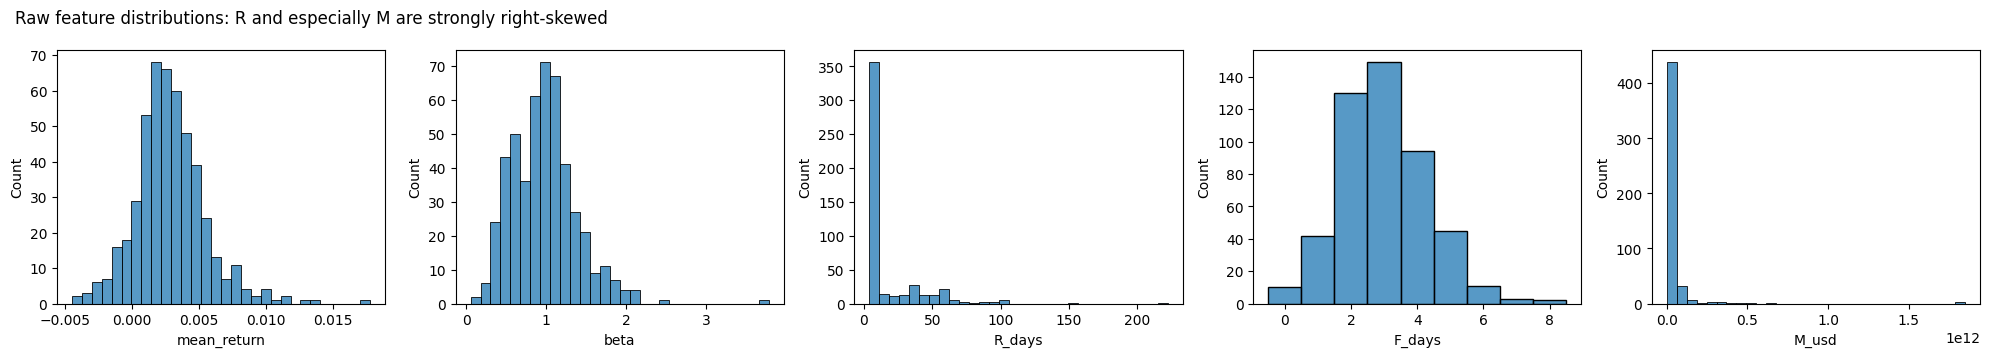

Skew of M: 11.68 raw → 1.08 after log1p


In [84]:
# Task 2.1 – Part 2: distributions of the five raw features (inspect skew and outliers)
# Step 1: one histogram per raw feature
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, col in zip(axes, raw_units.columns):
    sns.histplot(raw_units[col], bins=30, discrete=(col == "F_days"), ax=ax)   # F is a whole-number count
fig.suptitle("Raw feature distributions: R and especially M are strongly right-skewed", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "fig1_feature_distributions.png", dpi=200); plt.show()
# Step 2: show how much log1p reduces the skew of M
print(f"Skew of M: {prep['monetary_usd'].skew():.2f} raw → {prep['log1p_monetary'].skew():.2f} after log1p")

### 2.2 Agglomerative clustering – Ward linkage, Euclidean distance


Risk and return


,k,silhouette,smallest,sizes
0,2,0.339,92,"[394, 92]"
1,3,0.274,92,"[230, 164, 92]"
2,4,0.282,48,"[182, 164, 48, 92]"
3,5,0.304,48,"[182, 66, 98, 48, 92]"
4,6,0.320,5,"[182, 66, 98, 48, 87, 5]"
5,7,0.324,5,"[160, 66, 98, 48, 22, 87, 5]"
6,8,0.321,5,"[160, 66, 98, 48, 22, 56, 31, 5]"


RFM


,k,silhouette,smallest,sizes
0,2,0.368,82,"[404, 82]"
1,3,0.304,82,"[154, 250, 82]"
2,4,0.289,43,"[154, 207, 82, 43]"
3,5,0.305,10,"[154, 207, 72, 43, 10]"
4,6,0.314,10,"[136, 207, 18, 72, 43, 10]"
5,7,0.292,10,"[136, 66, 18, 72, 141, 43, 10]"
6,8,0.302,10,"[57, 66, 79, 18, 72, 141, 43, 10]"


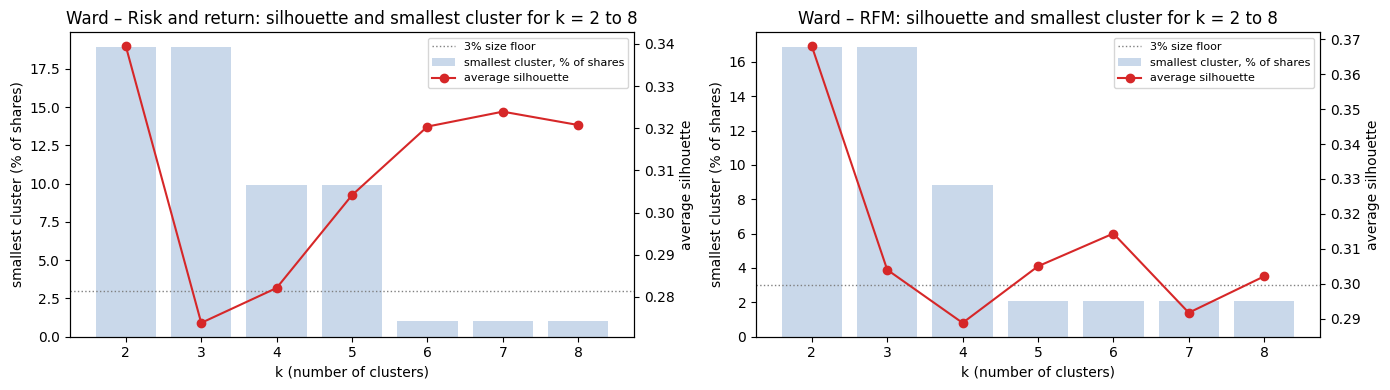

In [85]:
# Task 2.2 – Ward agglomerative clustering (Euclidean) for k = 2 to 8, with a k-comparison chart
# Step 1: for each matrix, build the Ward tree and cut it at k = 2..8
ward = {}
for name, X in matrices.items():
    tree = linkage(X.to_numpy(), method="ward", metric="euclidean")   # build the full Ward tree once
    rows, labels, profiles = [], {}, []
    for k in range(2, 9):
        lab = pd.Series(cut_tree(tree, n_clusters=k).ravel() + 1, index=X.index)   # cut it into k clusters (1..k)
        sizes = lab.value_counts().sort_index()
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "smallest": int(sizes.min()), "sizes": sizes.tolist()})
        labels[k] = lab
        profiles.append(raw_units.groupby(lab).median().assign(k=k, shares=sizes))   # median profile in original units
    ward[name] = {"tree": tree, "scores": pd.DataFrame(rows), "labels": labels}
    ward[name]["scores"].to_csv(OUT / f"ward_{name}_comparison.csv", index=False)
    pd.concat(profiles).to_csv(OUT / f"ward_{name}_profiles.csv")
    print(titles[name]); display(ward[name]["scores"].round(3))

# Step 2: chart: silhouette and smallest-cluster size for each k
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, matrices):
    sc = ward[name]["scores"]
    ax.bar(sc["k"], sc["smallest"] / len(stocks) * 100, color="#c9d8ea", label="smallest cluster, % of shares")
    ax.axhline(3, ls=":", c="grey", lw=1, label="3% size floor")
    ax.set_xlabel("k (number of clusters)"); ax.set_ylabel("smallest cluster (% of shares)")
    ax2 = ax.twinx()
    ax2.plot(sc["k"], sc["silhouette"], "o-", c="C3", label="average silhouette")
    ax2.set_ylabel("average silhouette")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
    ax.set_title(f"Ward – {titles[name]}: silhouette and smallest cluster for k = 2 to 8")
fig.tight_layout(); fig.savefig(FIG / "fig_2_2_ward_k_comparison.png", dpi=200); plt.show()

#### 2.2 Dendrograms (one per matrix) and merge heights

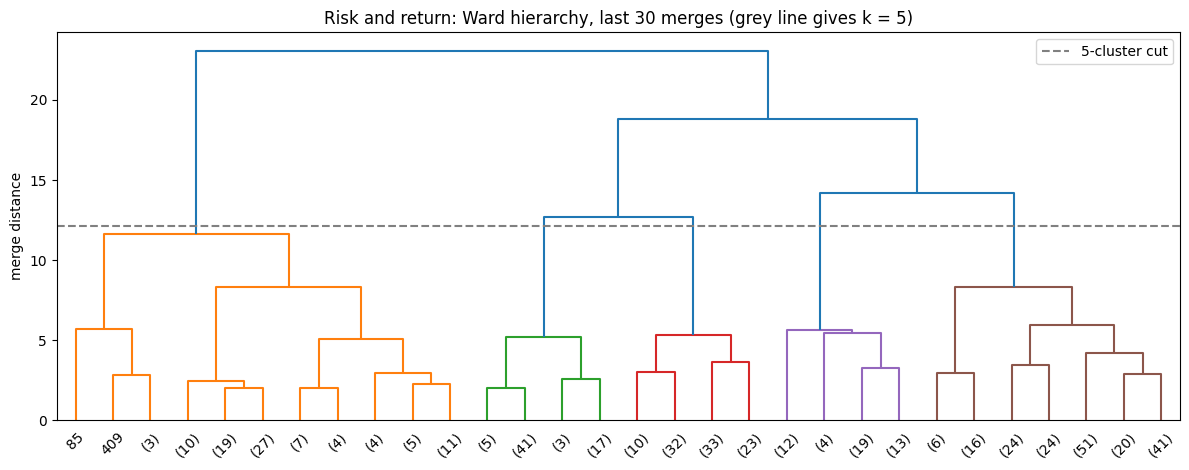

Risk and return – heights of the final merges (2→1, 3→2, …): [23.07 18.8  14.21 12.67]


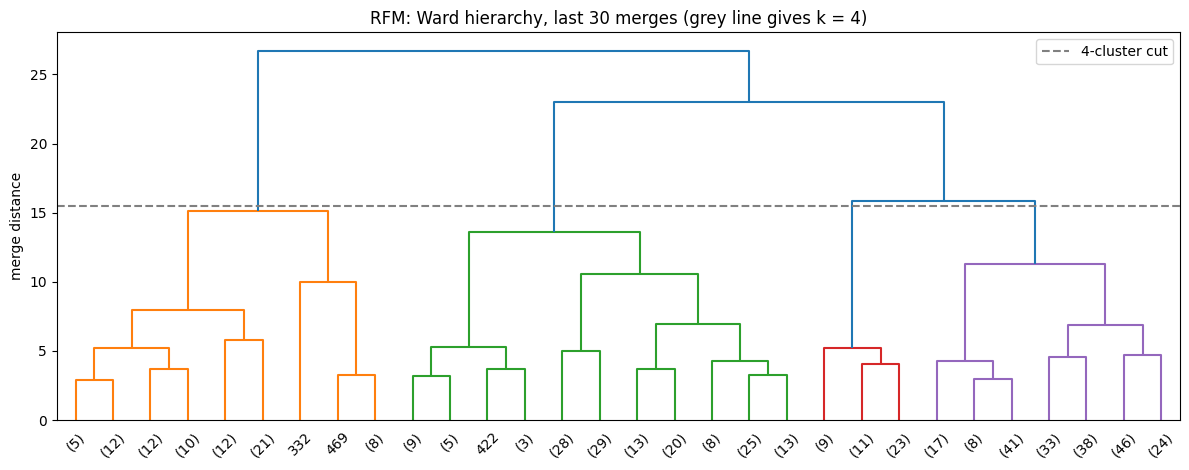

RFM – heights of the final merges (2→1, 3→2, …): [26.71 22.99 15.84 15.15]


matrix,rfm,risk_return
clusters_after_merge,,
1,1.16,1.23
2,1.45,1.32
3,1.05,1.12
4,1.12,1.09
5,1.20,1.39
6,1.07,1.00
7,1.06,1.40
8,1.25,1.04


In [86]:
# Task 2.2 – one dendrogram per matrix with the selected cut, and the heights of the last merges
# Step 1: draw one dendrogram per matrix with the chosen cut
selected_k = {"risk_return": 5, "rfm": 4}  # Manually defining selected_k to prevent NameError

heights = []
for name in matrices:
    tree, k = ward[name]["tree"], selected_k[name]
    cut = (tree[-k, 2] + tree[-k + 1, 2]) / 2                          # a height between the merges giving k and k-1 clusters
    fig, ax = plt.subplots(figsize=(12, 4.8))
    dendrogram(tree, truncate_mode="lastp", p=30, show_leaf_counts=True, color_threshold=cut, ax=ax)
    ax.axhline(cut, ls="--", c="grey", label=f"{k}-cluster cut")
    ax.set_title(f"{titles[name]}: Ward hierarchy, last 30 merges (grey line gives k = {k})")
    ax.set_ylabel("merge distance"); ax.legend()
    fig.tight_layout(); fig.savefig(FIG / f"fig_2_2_dendrogram_{name}.png", dpi=200); plt.show()
    top = tree[-8:, 2][::-1]
    print(f"{titles[name]} – heights of the final merges (2→1, 3→2, …): {np.round(top[:4], 2)}")
    for j in range(1, 9):
        # a big jump between merge heights would be a natural cut; small jumps = no clear natural k
        heights.append({"matrix": name, "clusters_after_merge": j, "merge_height": tree[-j, 2], "jump": tree[-j, 2] / tree[-j - 1, 2]})
# Step 2: save the merge heights
merge_heights = pd.DataFrame(heights)
merge_heights.to_csv(OUT / "ward_merge_heights.csv", index=False)

# Step 3: save both dendrograms side by side for the report
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, name in zip(axes, matrices):
    tree, k = ward[name]["tree"], selected_k[name]
    cut = (tree[-k, 2] + tree[-k + 1, 2]) / 2
    dendrogram(tree, truncate_mode="lastp", p=30, show_leaf_counts=True, color_threshold=cut, ax=ax)
    ax.axhline(cut, ls="--", c="grey"); ax.set_title(f"{titles[name]} (k = {k})"); ax.set_ylabel("merge distance")
fig.tight_layout(); fig.savefig(FIG / "fig3_ward_dendrograms.png", dpi=200); plt.close(fig)
merge_heights.pivot(index="clusters_after_merge", columns="matrix", values="jump").round(2)

### 2.3 K-means


Risk and return


,k,silhouette,inertia,smallest,sizes
0,2,0.387,621.634,143,"[143, 343]"
1,3,0.329,461.179,119,"[202, 165, 119]"
2,4,0.327,371.577,40,"[132, 154, 40, 160]"
3,5,0.341,309.613,27,"[112, 166, 131, 27, 50]"
4,6,0.335,265.097,5,"[156, 127, 50, 105, 43, 5]"
5,7,0.328,227.183,5,"[103, 85, 41, 128, 77, 47, 5]"
6,8,0.354,194.362,5,"[136, 43, 76, 78, 5, 29, 40, 79]"


RFM


,k,silhouette,inertia,smallest,sizes
0,2,0.423,1066.832,68,"[418, 68]"
1,3,0.325,796.614,64,"[270, 152, 64]"
2,4,0.341,609.832,61,"[122, 61, 212, 91]"
3,5,0.358,514.714,11,"[68, 122, 87, 11, 198]"
4,6,0.347,437.393,11,"[105, 143, 40, 11, 120, 67]"
5,7,0.347,386.286,1,"[141, 41, 104, 120, 1, 68, 11]"
6,8,0.350,342.175,1,"[15, 106, 64, 66, 1, 11, 140, 83]"


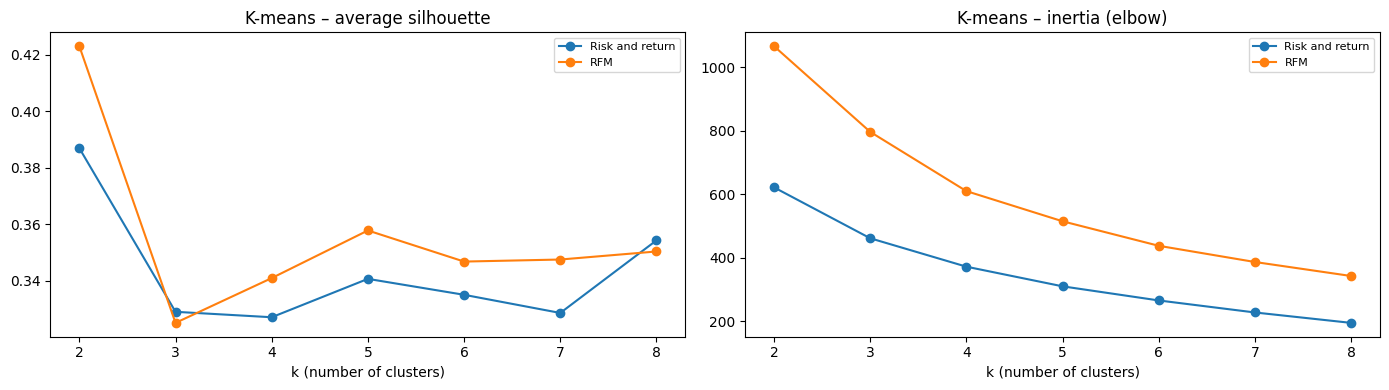

In [87]:
# Task 2.3 – K-means for k = 2 to 8 (seed 42, 50 starts), with a silhouette and inertia chart
# Step 1: for each matrix, run K-means for k = 2..8
kmeans = {}
for name, X in matrices.items():
    rows, labels = [], {}
    for k in range(2, 9):
        model = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)   # 50 starts, best one kept
        lab = pd.Series(model.labels_ + 1, index=X.index)
        sizes = lab.value_counts().sort_index()
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "inertia": model.inertia_,
                     "smallest": int(sizes.min()), "sizes": sizes.tolist()})
        labels[k] = lab
    kmeans[name] = {"scores": pd.DataFrame(rows), "labels": labels}
    kmeans[name]["scores"].to_csv(OUT / f"kmeans_{name}_comparison.csv", index=False)
    print(titles[name]); display(kmeans[name]["scores"].round(3))

# Step 2: chart: K-means silhouette and inertia
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name in matrices:
    axes[0].plot(kmeans[name]["scores"]["k"], kmeans[name]["scores"]["silhouette"], "o-", label=titles[name])
    axes[1].plot(kmeans[name]["scores"]["k"], kmeans[name]["scores"]["inertia"], "o-", label=titles[name])
for ax, t in zip(axes, ["K-means – average silhouette", "K-means – inertia (elbow)"]):
    ax.set_title(t); ax.set_xlabel("k (number of clusters)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig_2_3_kmeans_k_comparison.png", dpi=200); plt.show()

# Step 3: save a combined figure for the report
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for name in matrices:
    axes[0].plot(ward[name]["scores"]["k"], ward[name]["scores"]["silhouette"], "o-", label=titles[name])
    axes[1].plot(kmeans[name]["scores"]["k"], kmeans[name]["scores"]["silhouette"], "o-", label=titles[name])
    axes[2].plot(kmeans[name]["scores"]["k"], kmeans[name]["scores"]["inertia"], "o-", label=titles[name])
for ax, t in zip(axes, ["Ward – average silhouette", "K-means – average silhouette", "K-means – inertia (elbow)"]):
    ax.set_title(t); ax.set_xlabel("k"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig2_k_selection.png", dpi=200); plt.close(fig)

In [88]:
# Task 2.2 / 2.3 – choose one k per matrix with a written rule, then keep the four baseline solutions
# Step 1: apply the k-selection rule to each matrix
selected_k, tables = {}, {}
for name in matrices:
    w, km = ward[name]["scores"].set_index("k"), kmeans[name]["scores"].set_index("k")
    t = pd.DataFrame({"ward": w["silhouette"], "kmeans": km["silhouette"]})
    t["average"] = t.mean(axis=1)
    t["smallest_cluster"] = np.minimum(w["smallest"], km["smallest"])
    t["sizes_ok"] = t["smallest_cluster"] >= 0.03 * len(stocks)
    selected_k[name] = int(t[(t.index >= 3) & t["sizes_ok"]]["average"].idxmax())
    tables[name] = t
    print(f"{titles[name]}: k = {selected_k[name]}"); display(t.round(3))
pd.concat(tables, names=["matrix"]).to_csv(OUT / "k_selection_table.csv")

# Step 2: keep the four baseline solutions and save their memberships
memberships = {}
for name, k in selected_k.items():
    memberships["ward", name] = ward[name]["labels"][k]
    memberships["kmeans", name] = kmeans[name]["labels"][k]
    memberships["ward", name].to_csv(OUT / f"ward_{name}_selected_membership.csv", header=["cluster"])
    memberships["kmeans", name].to_csv(OUT / f"kmeans_{name}_selected_membership.csv", header=["cluster"])

Risk and return: k = 5


,ward,kmeans,average,smallest_cluster,sizes_ok
k,,,,,
2,0.339,0.387,0.363,92,True
3,0.274,0.329,0.301,92,True
4,0.282,0.327,0.305,40,True
5,0.304,0.341,0.322,27,True
6,0.320,0.335,0.328,5,False
7,0.324,0.328,0.326,5,False
8,0.321,0.354,0.338,5,False


RFM: k = 4


,ward,kmeans,average,smallest_cluster,sizes_ok
k,,,,,
2,0.368,0.423,0.396,68,True
3,0.304,0.325,0.314,64,True
4,0.289,0.341,0.315,43,True
5,0.305,0.358,0.331,10,False
6,0.314,0.347,0.331,10,False
7,0.292,0.347,0.320,1,False
8,0.302,0.350,0.326,1,False


#### Choosing k (one k per matrix, used by both algorithms)


In [89]:
# Task 2.3 – K-means stability: does a different seed give the same clusters?
# Step 1: refit K-means with seeds 1-5 and compare with the ARI
for name, k in selected_k.items():
    ari = [adjusted_rand_score(memberships["kmeans", name], KMeans(n_clusters=k, n_init=N_INIT, random_state=s).fit_predict(matrices[name]))
           for s in range(1, 6)]
    print(f"{titles[name]}: ARI against seeds 1-5 = {np.round(ari, 3)}")

Risk and return: ARI against seeds 1-5 = [0.91  0.959 0.916 0.93  0.965]
RFM: ARI against seeds 1-5 = [1.    0.994 1.    0.994 1.   ]


### 2.4 Cluster profiles and algorithm comparison


In [90]:
# Task 2.4 – Part 1: cluster profiles in original units (medians)
# Step 1: the features in readable units
profile_cols = pd.DataFrame({"Mean weekly return (%)": stocks["mean_weekly_return"] * 100, "Weekly beta": stocks["weekly_beta"],
                             "Weekly volatility (%)": stocks["weekly_volatility"] * 100, "Recency (days)": stocks["recency_days"].astype(float),
                             "Frequency (days)": stocks["frequency_days"], "Monetary (USD bn)": stocks["monetary_usd"] / 1e9})
# Step 2: a profile = number of shares + median of each feature
def profile(lab):
    g = profile_cols.groupby(lab.rename("cluster"))
    return g.median().round(3).assign(shares=g.size())

# Step 3: show and save the profile of every baseline solution
for (alg, name), lab in memberships.items():
    profile(lab).to_csv(OUT / f"{alg}_{name}_selected_profiles.csv")
    print(f"{alg} – {titles[name]} (k = {selected_k[name]})"); display(profile(lab))

ward – Risk and return (k = 5)


,Mean weekly return (%),Weekly beta,Weekly volatility (%),Recency (days),Frequency (days),Monetary (USD bn),shares
cluster,,,,,,,
1,0.166,0.964,3.789,11.0,3.0,12.985,182
2,0.113,0.448,2.970,11.0,3.0,17.701,66
3,0.392,0.666,3.382,11.0,3.0,17.649,98
4,0.252,1.514,5.922,11.0,3.0,28.698,48
5,0.550,1.218,4.706,11.0,3.0,24.184,92


kmeans – Risk and return (k = 5)


,Mean weekly return (%),Weekly beta,Weekly volatility (%),Recency (days),Frequency (days),Monetary (USD bn),shares
cluster,,,,,,,
1,0.075,1.032,3.997,11.0,3.0,13.503,112
2,0.415,0.996,3.930,11.0,3.0,17.720,166
3,0.203,0.530,3.064,11.0,3.0,15.044,131
4,0.831,1.450,5.877,11.0,3.0,28.211,27
5,0.267,1.543,5.952,11.0,3.0,32.148,50


ward – RFM (k = 4)


,Mean weekly return (%),Weekly beta,Weekly volatility (%),Recency (days),Frequency (days),Monetary (USD bn),shares
cluster,,,,,,,
1,0.325,0.989,3.932,11.0,3.0,39.695,154
2,0.244,0.924,3.778,11.0,3.0,10.785,207
3,0.244,1.047,4.188,54.5,2.0,17.849,82
4,0.276,1.047,3.798,11.0,5.0,14.430,43


kmeans – RFM (k = 4)


,Mean weekly return (%),Weekly beta,Weekly volatility (%),Recency (days),Frequency (days),Monetary (USD bn),shares
cluster,,,,,,,
1,0.253,0.922,3.792,11.0,4.0,12.826,122
2,0.253,1.051,4.037,55.0,2.0,21.242,61
3,0.259,0.931,3.785,11.0,2.0,13.336,212
4,0.295,1.048,4.113,11.0,3.0,60.183,91


In [91]:
# Task 2.4 – Part 2: cluster names and the Ward vs K-means comparison on the same shares
# Step 1: name the Ward clusters from their profiles
NAMES = {"risk_return": {1: "Core market-like", 2: "Defensive low-beta", 3: "Low-beta outperformers", 4: "High-beta volatile", 5: "High-return growth"},
         "rfm": {1: "High-value liquid", 2: "Lower-value routine", 3: "Quiet recently", 4: "Frequent surges"}}
# Step 2: compare Ward and K-means on the same shares (ARI and a cross-table)
ari_algorithms = {}
for name in matrices:
    w, km = memberships["ward", name], memberships["kmeans", name]
    ari_algorithms[name] = adjusted_rand_score(w, km)                 # ARI ignores cluster numbering; 1 = identical
    table = pd.crosstab(w.map(NAMES[name]).rename("Ward"), km.rename("K-means"))
    table.to_csv(OUT / f"{name}_algorithm_overlap.csv")
    print(f"{titles[name]}: Ward vs K-means ARI = {ari_algorithms[name]:.3f}"); display(table)

Risk and return: Ward vs K-means ARI = 0.318


K-means,1,2,3,4,5
Ward,,,,,
Core market-like,104,49,29,0,0
Defensive low-beta,5,0,61,0,0
High-beta volatile,3,0,0,0,45
High-return growth,0,60,0,27,5
Low-beta outperformers,0,57,41,0,0


RFM: Ward vs K-means ARI = 0.343


K-means,1,2,3,4
Ward,,,,
Frequent surges,43,0,0,0
High-value liquid,14,4,52,84
Lower-value routine,61,0,146,0
Quiet recently,4,57,14,7


PCA keeps 79.4% of the RFM variance (PC1 45.8%, PC2 33.6%)


,PC1,PC2
recency_days,0.711,0.023
frequency_days,-0.650,0.402
log1p_monetary,0.268,0.915


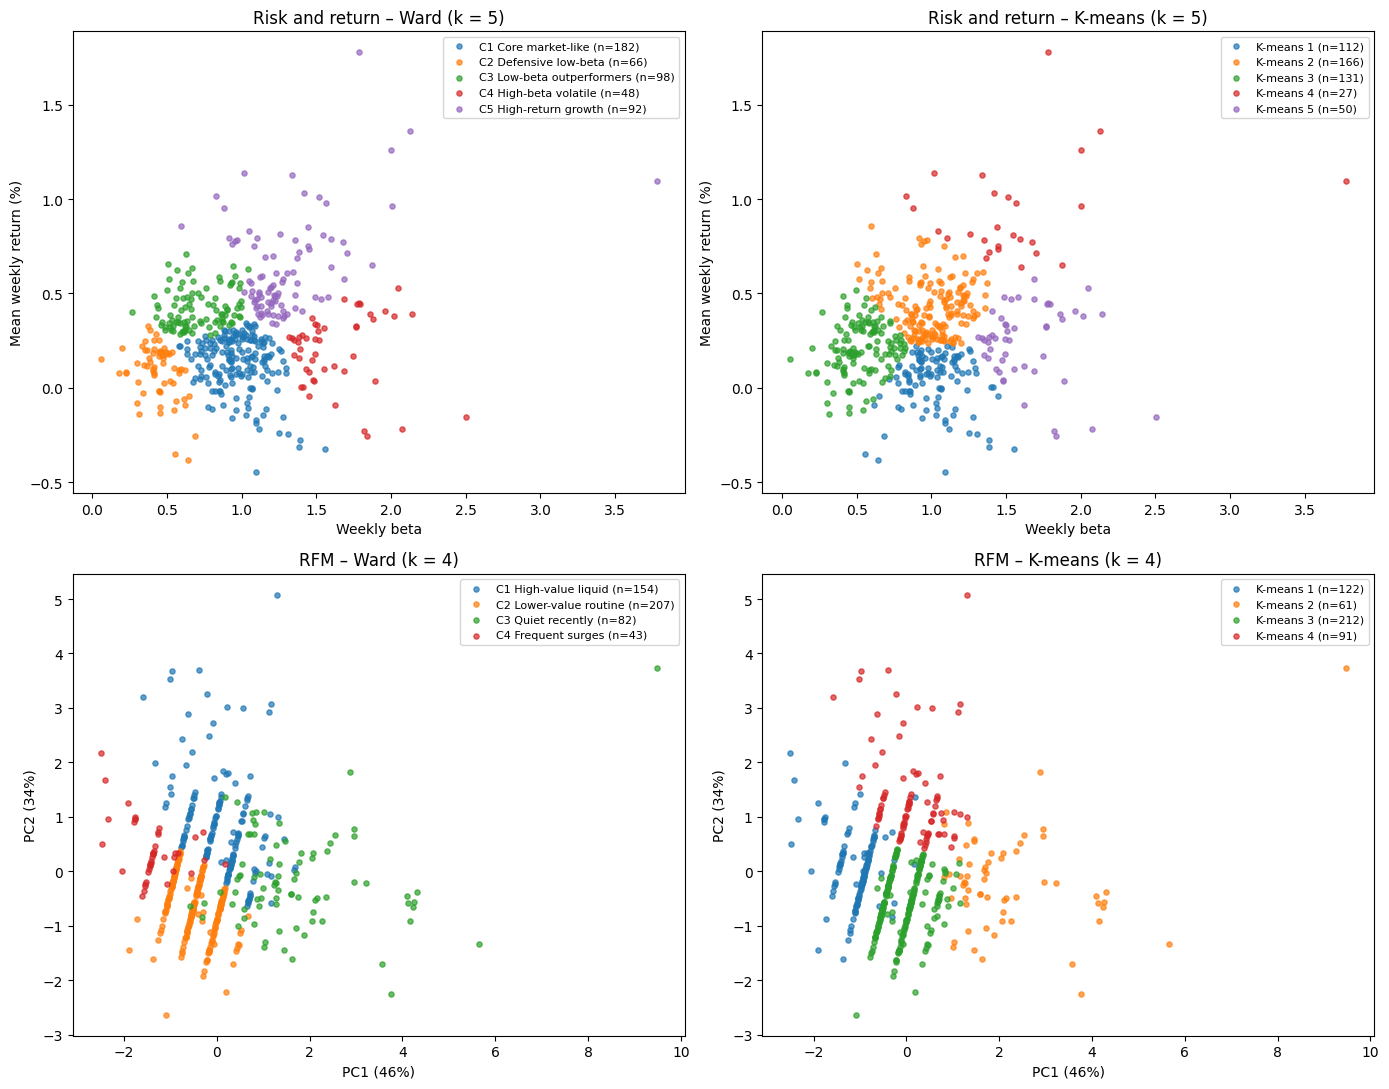

In [92]:
# Task 2.4 – Part 3: labelled 2-D plots (risk–return directly, RFM through PCA)
# Step 1: PCA: squeeze the three RFM features into two for plotting
pca = PCA(n_components=2).fit(X_rfm)
xy = pd.DataFrame(pca.transform(X_rfm), index=X_rfm.index)
explained = pca.explained_variance_ratio_ * 100                      # % of variance the 2-D picture keeps
loadings = pd.DataFrame(pca.components_.T, index=X_rfm.columns, columns=["PC1", "PC2"])
loadings.round(3).to_csv(OUT / "rfm_pca_loadings.csv")
print(f"PCA keeps {explained.sum():.1f}% of the RFM variance (PC1 {explained[0]:.1f}%, PC2 {explained[1]:.1f}%)"); display(loadings.round(3))

# Step 2: plot every baseline solution with labelled clusters
axes_xy = {"risk_return": (profile_cols["Weekly beta"], profile_cols["Mean weekly return (%)"], "Weekly beta", "Mean weekly return (%)"),
           "rfm": (xy[0], xy[1], f"PC1 ({explained[0]:.0f}%)", f"PC2 ({explained[1]:.0f}%)")}
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for r, name in enumerate(matrices):
    x, y, xl, yl = axes_xy[name]
    for c, alg in enumerate(["ward", "kmeans"]):
        lab, ax = memberships[alg, name], axes[r, c]
        for cl in sorted(lab.unique()):
            m = lab == cl
            ax.scatter(x[m], y[m], s=14, alpha=0.7, label=(f"C{cl} {NAMES[name][cl]}" if alg == "ward" else f"K-means {cl}") + f" (n={m.sum()})")
        ax.set_title(f"{titles[name]} – {'Ward' if alg == 'ward' else 'K-means'} (k = {selected_k[name]})")
        ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig4_cluster_scatter.png", dpi=200); plt.show()

### 2.5 RFM sensitivity
#### 2.5.1 Correlations among R, F and log1p(M)

Spearman (rank) correlations:


,recency_days,frequency_days,log1p_monetary
recency_days,1.000,-0.196,0.137
frequency_days,-0.196,1.000,-0.048
log1p_monetary,0.137,-0.048,1.000


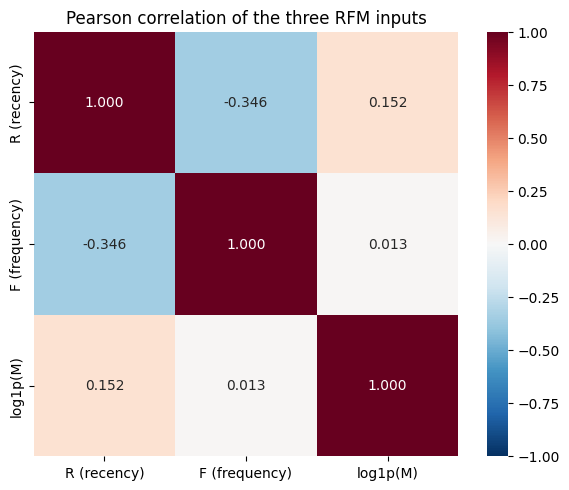

In [93]:
# Task 2.5.1 – correlations among R, F and log1p(M), with a heatmap
# Step 1: Pearson and Spearman correlations among R, F and log1p(M)
rfm_corr_input = stocks[["recency_days", "frequency_days"]].astype(float).assign(log1p_monetary=np.log1p(stocks["monetary_usd"]))
pearson, spearman = rfm_corr_input.corr(), rfm_corr_input.corr("spearman")   # linear and rank correlations
pearson.to_csv(OUT / "rfm_correlations.csv"); spearman.to_csv(OUT / "rfm_correlations_spearman.csv")
print("Spearman (rank) correlations:"); display(spearman.round(3))

# Step 2: heatmap of the Pearson correlations
labels = ["R (recency)", "F (frequency)", "log1p(M)"]
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(pd.DataFrame(pearson.values, index=labels, columns=labels), annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson correlation of the three RFM inputs")
fig.tight_layout(); fig.savefig(FIG / "fig_2_5_1_rfm_correlation_heatmap.png", dpi=200); plt.show()

#### 2.5.2 Removing Monetary


486 shares, k = 4: ARI between the solutions with and without M = 0.203


R and F only,1,2,3,4
with M,,,,
Frequent surges,42,0,1,0
High-value liquid,86,59,9,0
Lower-value routine,141,66,0,0
Quiet recently,3,0,69,10


,with M: median $bn,R and F only: median $bn
1,39.7,14.9
2,10.8,17.7
3,17.8,20.1
4,14.4,23.8


Highest/lowest cluster median traded value: {'with M: median $bn': 3.68, 'R and F only: median $bn': 1.6}
Robustness: replacing R with log1p(R) gives ARI = 0.757


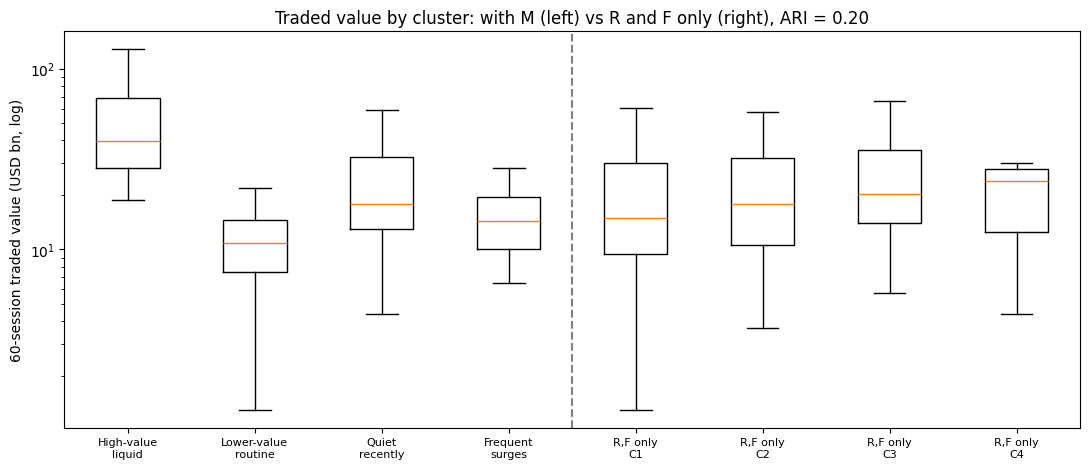

In [94]:
# Task 2.5.2 – remove Monetary: refit the selected Ward RFM model with R and F only and compare
# Step 1: refit the chosen Ward RFM model with R and F only and compare (ARI)
full, k = memberships["ward", "rfm"], selected_k["rfm"]
X_rf = StandardScaler().fit_transform(stocks[["recency_days", "frequency_days"]].astype(float))   # R and F only, scaled afresh
reduced = pd.Series(cut_tree(linkage(X_rf, method="ward"), n_clusters=k).ravel() + 1, index=full.index)   # same shares, same k
ari_m = adjusted_rand_score(full, reduced)                            # low ARI = Monetary changes the clusters a lot
overlap = pd.crosstab(full.map(NAMES["rfm"]).rename("with M"), reduced.rename("R and F only"))
overlap.to_csv(OUT / "ward_rfm_sensitivity_overlap.csv")
print(f"{len(full)} shares, k = {k}: ARI between the solutions with and without M = {ari_m:.3f}"); display(overlap)

# Step 2: traded value per cluster with and without M
m_bn = stocks["monetary_usd"] / 1e9
m_profile = pd.DataFrame({"with M: median $bn": m_bn.groupby(full).median(), "R and F only: median $bn": m_bn.groupby(reduced).median()})
m_profile.to_csv(OUT / "ward_rfm_sensitivity_profiles.csv")
pd.DataFrame({"with_m": full, "r_f_only": reduced}).to_csv(OUT / "ward_rfm_sensitivity_membership.csv")
spread = (m_profile.max() / m_profile.min()).round(2)
display(m_profile.round(1))
print("Highest/lowest cluster median traded value:", spread.to_dict())

# Step 3: robustness check with log1p(R)
X_logr = StandardScaler().fit_transform(rfm_input.assign(recency_days=np.log1p(rfm_input["recency_days"])))
ari_logr = adjusted_rand_score(full, cut_tree(linkage(X_logr, method="ward"), n_clusters=k).ravel() + 1)
print(f"Robustness: replacing R with log1p(R) gives ARI = {ari_logr:.3f}")

# Step 4: box plot of traded value with M (left) and without M (right)
fig, ax = plt.subplots(figsize=(11, 4.8))
groups = [m_bn[full == c] for c in range(1, k + 1)] + [m_bn[reduced == c] for c in range(1, k + 1)]
ax.boxplot(groups, showfliers=False)
ax.set_xticks(range(1, 2 * k + 1))
ax.set_xticklabels([NAMES["rfm"][c].replace(" ", "\n", 1) for c in range(1, k + 1)] + [f"R,F only\nC{c}" for c in range(1, k + 1)], fontsize=8)
ax.set_yscale("log"); ax.axvline(k + 0.5, ls="--", c="grey")
ax.set_ylabel("60-session traded value (USD bn, log)"); ax.set_title(f"Traded value by cluster: with M (left) vs R and F only (right), ARI = {ari_m:.2f}")
fig.tight_layout(); fig.savefig(FIG / "fig5_monetary_removal.png", dpi=200); plt.show()

## Task 3 – Business intelligence and review


Risk and return


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
row_0,,,,,,,,,,,
Core market-like,3.8,9.3,2.7,0.0,14.3,13.7,22.0,11.0,7.7,12.6,2.7
Defensive low-beta,4.5,0.0,33.3,0.0,3.0,28.8,3.0,0.0,1.5,1.5,24.2
High-beta volatile,0.0,20.8,0.0,0.0,10.4,8.3,8.3,47.9,4.2,0.0,0.0
High-return growth,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1
Low-beta outperformers,5.1,9.2,5.1,16.3,28.6,8.2,11.2,2.0,3.1,3.1,8.2


RFM


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
row_0,,,,,,,,,,,
Frequent surges,4.7,9.3,4.7,2.3,7.0,20.9,25.6,14.0,2.3,4.7,4.7
High-value liquid,5.8,13.0,7.1,6.5,16.2,13.6,13.6,20.1,1.3,1.9,0.6
Lower-value routine,2.4,6.8,5.8,3.4,17.4,9.2,19.3,9.2,5.8,12.1,8.7
Quiet recently,4.9,11.0,8.5,2.4,12.2,11.0,7.3,22.0,9.8,0.0,11.0


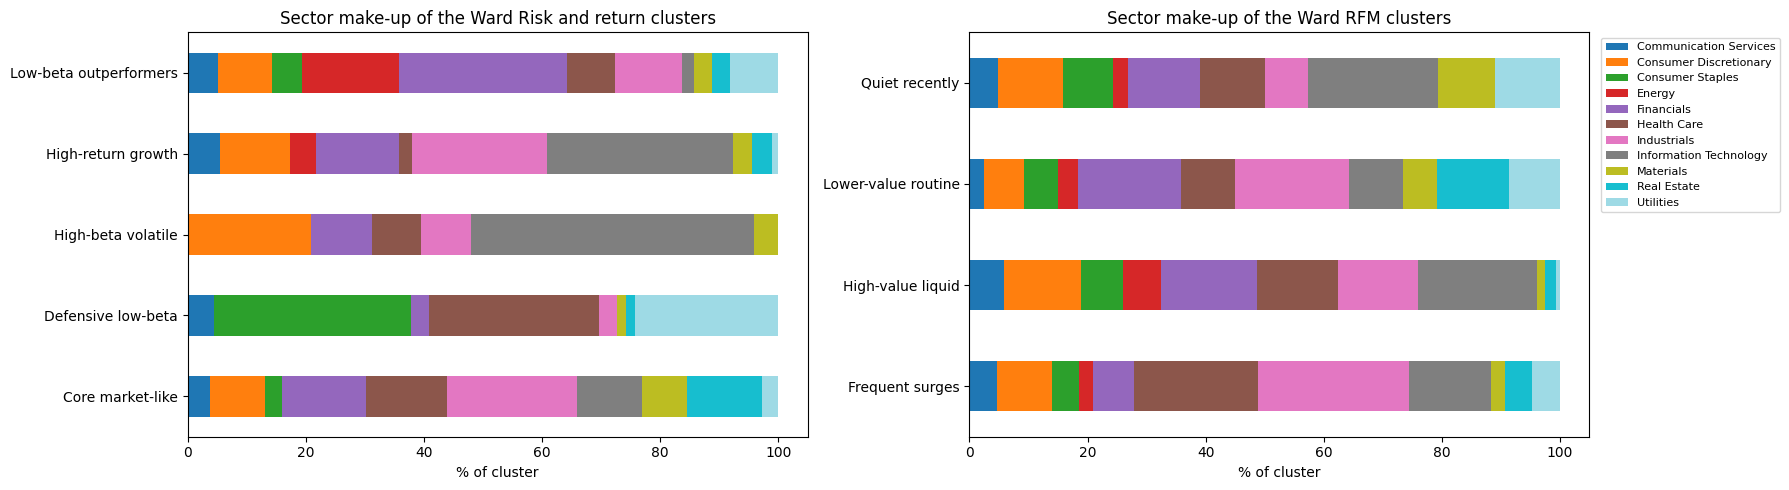

Agreement between the risk–return and RFM segmentations: ARI = 0.040


RFM,Frequent surges,High-value liquid,Lower-value routine,Quiet recently
risk–return,,,,
Core market-like,15,39,100,28
Defensive low-beta,4,23,23,16
High-beta volatile,6,20,13,9
High-return growth,12,37,24,19
Low-beta outperformers,6,35,47,10


In [95]:
# Task 3.2.1 – sector make-up of the clusters and agreement between the two segmentations
# Step 1: sector percentages in every Ward cluster, with a stacked bar chart
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, name in zip(axes, matrices):
    pct = pd.crosstab(memberships["ward", name].map(NAMES[name]), stocks["sector"], normalize="index") * 100
    pct.round(1).to_csv(OUT / f"{name}_sector_percentages.csv")
    pct.plot.barh(stacked=True, ax=ax, colormap="tab20", legend=(name == "rfm"))
    ax.set_title(f"Sector make-up of the Ward {titles[name]} clusters"); ax.set_xlabel("% of cluster"); ax.set_ylabel("")
    print(titles[name]); display(pct.round(1))
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig6_sector_composition.png", dpi=200); plt.show()

# Step 2: agreement between the two segmentations
ari_cross = adjusted_rand_score(memberships["ward", "risk_return"], memberships["ward", "rfm"])
cross = pd.crosstab(memberships["ward", "risk_return"].map(NAMES["risk_return"]).rename("risk–return"),
                    memberships["ward", "rfm"].map(NAMES["rfm"]).rename("RFM"))
cross.to_csv(OUT / "crosstab_risk_return_vs_rfm.csv")
print(f"Agreement between the risk–return and RFM segmentations: ARI = {ari_cross:.3f}"); cross

#### 3.2.1 Sector composition of all four solutions (share counts)

Sector composition: ward – Risk and return (k = 5), number of shares


Cluster,Core market-like,Defensive low-beta,High-beta volatile,High-return growth,Low-beta outperformers,Total
Sector,,,,,,
Communication Services,7,3,0,5,5,20
Consumer Discretionary,17,0,10,11,9,47
Consumer Staples,5,22,0,0,5,32
Energy,0,0,0,4,16,20
Financials,26,2,5,13,28,74
Health Care,25,19,4,2,8,58
Industrials,40,2,4,21,11,78
Information Technology,20,0,23,29,2,74
Materials,14,1,2,3,3,23


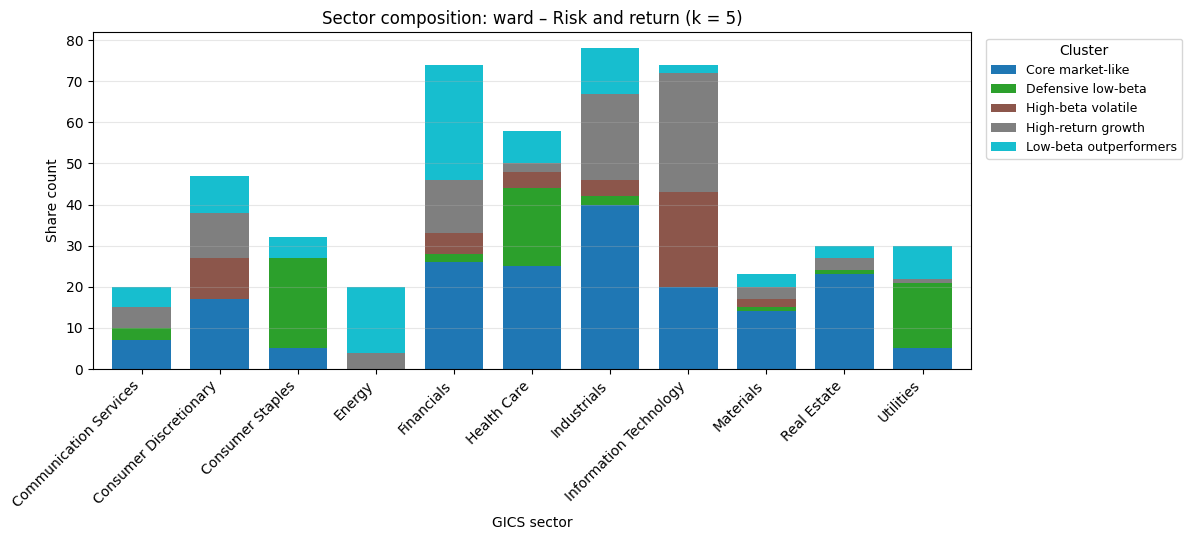

Sector percentages within each ward – Risk and return cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
Core market-like,3.8,9.3,2.7,0.0,14.3,13.7,22.0,11.0,7.7,12.6,2.7
Defensive low-beta,4.5,0.0,33.3,0.0,3.0,28.8,3.0,0.0,1.5,1.5,24.2
High-beta volatile,0.0,20.8,0.0,0.0,10.4,8.3,8.3,47.9,4.2,0.0,0.0
High-return growth,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1
Low-beta outperformers,5.1,9.2,5.1,16.3,28.6,8.2,11.2,2.0,3.1,3.1,8.2


Sector composition: kmeans – Risk and return (k = 5), number of shares


Cluster,K-means 1,K-means 2,K-means 3,K-means 4,K-means 5,Total
Sector,,,,,,
Communication Services,5,8,6,0,1,20
Consumer Discretionary,11,20,3,3,10,47
Consumer Staples,5,2,25,0,0,32
Energy,0,17,1,2,0,20
Financials,11,37,17,4,5,74
Health Care,25,8,24,0,1,58
Industrials,22,34,12,6,4,78
Information Technology,12,22,3,10,27,74
Materials,8,5,7,1,2,23


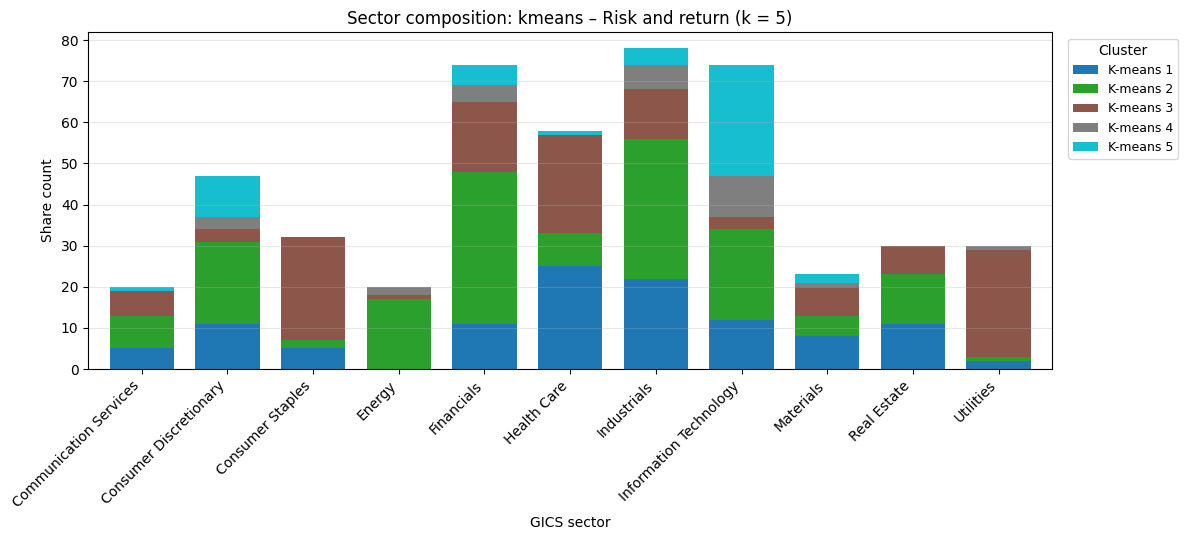

Sector percentages within each kmeans – Risk and return cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
K-means 1,4.5,9.8,4.5,0.0,9.8,22.3,19.6,10.7,7.1,9.8,1.8
K-means 2,4.8,12.0,1.2,10.2,22.3,4.8,20.5,13.3,3.0,7.2,0.6
K-means 3,4.6,2.3,19.1,0.8,13.0,18.3,9.2,2.3,5.3,5.3,19.8
K-means 4,0.0,11.1,0.0,7.4,14.8,0.0,22.2,37.0,3.7,0.0,3.7
K-means 5,2.0,20.0,0.0,0.0,10.0,2.0,8.0,54.0,4.0,0.0,0.0


Sector composition: ward – RFM (k = 4), number of shares


Cluster,Frequent surges,High-value liquid,Lower-value routine,Quiet recently,Total
Sector,,,,,
Communication Services,2,9,5,4,20
Consumer Discretionary,4,20,14,9,47
Consumer Staples,2,11,12,7,32
Energy,1,10,7,2,20
Financials,3,25,36,10,74
Health Care,9,21,19,9,58
Industrials,11,21,40,6,78
Information Technology,6,31,19,18,74
Materials,1,2,12,8,23


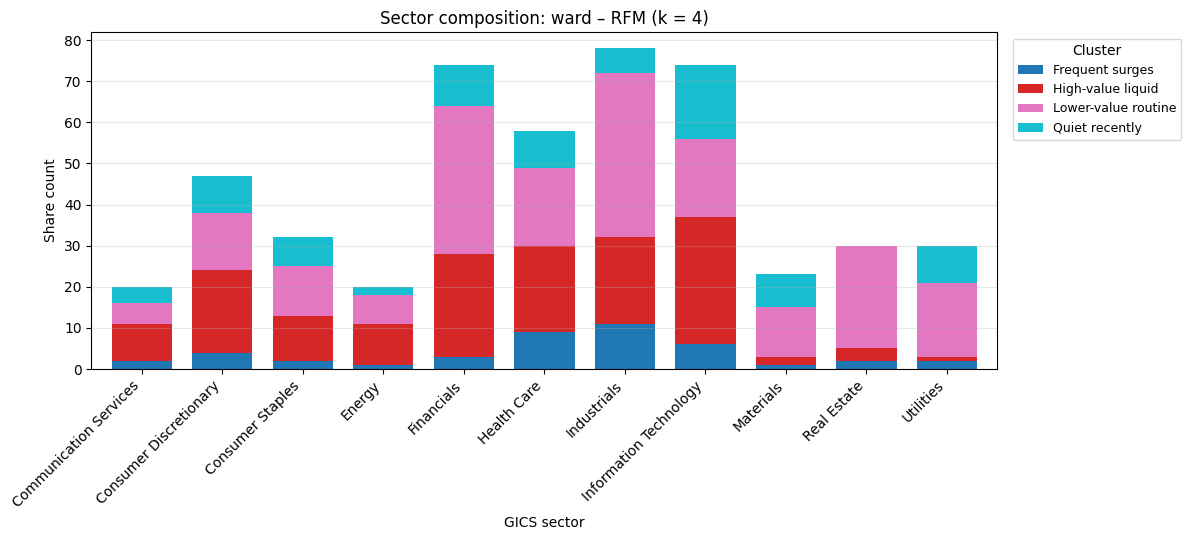

Sector percentages within each ward – RFM cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
Frequent surges,4.7,9.3,4.7,2.3,7.0,20.9,25.6,14.0,2.3,4.7,4.7
High-value liquid,5.8,13.0,7.1,6.5,16.2,13.6,13.6,20.1,1.3,1.9,0.6
Lower-value routine,2.4,6.8,5.8,3.4,17.4,9.2,19.3,9.2,5.8,12.1,8.7
Quiet recently,4.9,11.0,8.5,2.4,12.2,11.0,7.3,22.0,9.8,0.0,11.0


Sector composition: kmeans – RFM (k = 4), number of shares


Cluster,K-means 1,K-means 2,K-means 3,K-means 4,Total
Sector,,,,,
Communication Services,6,2,4,8,20
Consumer Discretionary,9,7,20,11,47
Consumer Staples,7,5,13,7,32
Energy,1,1,14,4,20
Financials,19,8,34,13,74
Health Care,19,6,19,14,58
Industrials,24,4,43,7,78
Information Technology,12,13,24,25,74
Materials,5,6,11,1,23


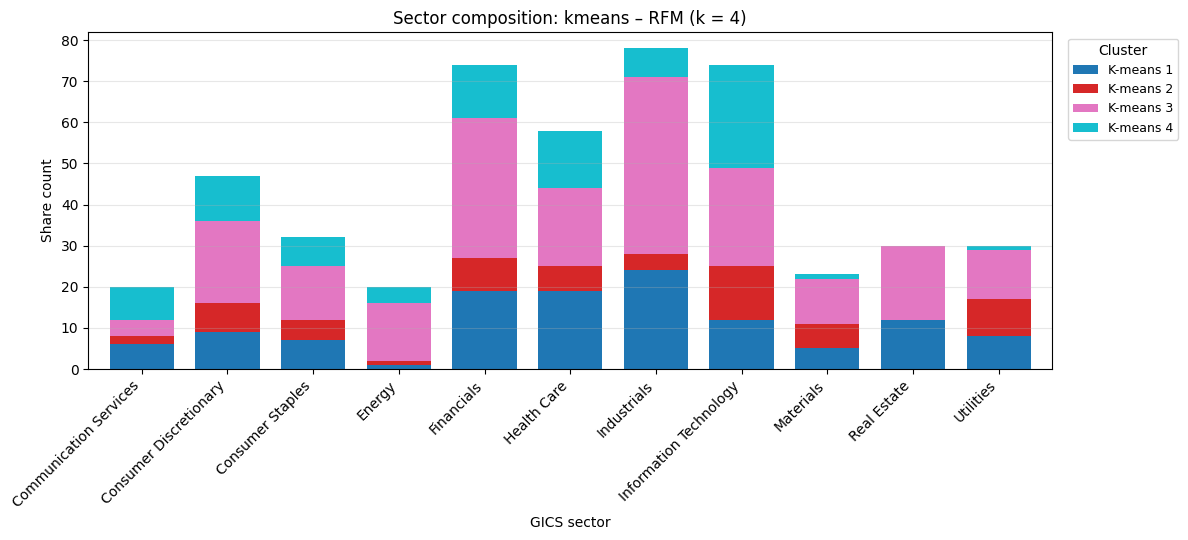

Sector percentages within each kmeans – RFM cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
K-means 1,4.9,7.4,5.7,0.8,15.6,15.6,19.7,9.8,4.1,9.8,6.6
K-means 2,3.3,11.5,8.2,1.6,13.1,9.8,6.6,21.3,9.8,0.0,14.8
K-means 3,1.9,9.4,6.1,6.6,16.0,9.0,20.3,11.3,5.2,8.5,5.7
K-means 4,8.8,12.1,7.7,4.4,14.3,15.4,7.7,27.5,1.1,0.0,1.1


In [96]:
# Task 3.2.1 – Part 2: sector composition of all four baseline solutions (share counts, stacked by cluster)
# Step 1: loop over the four solutions (Ward and K-means, for each matrix)
for (alg, name), lab in memberships.items():
    # Ward clusters get their names; K-means clusters keep their numbers
    cluster = lab.map(NAMES[name]) if alg == "ward" else lab.map(lambda c: f"K-means {c}")
    # Step 2: count the shares of each sector in each cluster
    counts = pd.crosstab(stocks["sector"].rename("Sector"), cluster.rename("Cluster"))
    counts["Total"] = counts.sum(axis=1)
    counts.to_csv(OUT / f"sector_counts_{alg}_{name}.csv")
    print(f"Sector composition: {alg} – {titles[name]} (k = {selected_k[name]}), number of shares")
    display(counts)

    # Step 3: stacked bar chart – one bar per sector, one colour per cluster
    fig, ax = plt.subplots(figsize=(12, 5.5))
    counts.drop(columns="Total").plot.bar(stacked=True, ax=ax, colormap="tab10", width=0.75)
    ax.set_title(f"Sector composition: {alg} – {titles[name]} (k = {selected_k[name]})")
    ax.set_xlabel("GICS sector"); ax.set_ylabel("Share count")
    ax.tick_params(axis="x", labelrotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Cluster", fontsize=9, bbox_to_anchor=(1.01, 1), loc="upper left")   # legend outside the bars
    fig.tight_layout(); fig.savefig(FIG / f"fig_3_sector_counts_{alg}_{name}.png", dpi=200); plt.show()

    # Step 4: the same table as percentages of each cluster (which sectors dominate each cluster)
    pct = (pd.crosstab(cluster.rename("Cluster"), stocks["sector"].rename("Sector"), normalize="index") * 100).round(1)
    pct.to_csv(OUT / f"sector_percentages_{alg}_{name}.csv")
    print(f"Sector percentages within each {alg} – {titles[name]} cluster:")
    display(pct)

In [97]:
# Task 3.2.3 – return dependence: how correlated are weekly returns within and across the risk–return clusters?
# Step 1: correlation of weekly returns between every pair of shares
corr = weekly_returns[stocks.index].corr()                            # 486 x 486 weekly-return correlations
# Step 2: average correlation within and between the risk-return clusters
lab = memberships["ward", "risk_return"]
names = [NAMES["risk_return"][c] for c in range(1, selected_k["risk_return"] + 1)]
dependence = pd.DataFrame(index=names, columns=names, dtype=float)
for a in range(1, len(names) + 1):
    for b in range(1, len(names) + 1):
        block = corr.loc[lab.index[lab == a], lab.index[lab == b]].to_numpy()
        dependence.iloc[a - 1, b - 1] = (block[np.triu_indices_from(block, 1)] if a == b else block).mean()
overall = corr.to_numpy()[np.triu_indices(len(corr), 1)].mean()
dependence.round(3).to_csv(OUT / "return_correlation_by_cluster.csv")
print(f"Mean pairwise weekly-return correlation across all {len(corr)} shares: {overall:.3f}")
dependence.round(3)

Mean pairwise weekly-return correlation across all 486 shares: 0.300


,Core market-like,Defensive low-beta,Low-beta outperformers,High-beta volatile,High-return growth
Core market-like,0.367,0.236,0.299,0.347,0.338
Defensive low-beta,0.236,0.312,0.238,0.125,0.149
Low-beta outperformers,0.299,0.238,0.325,0.234,0.275
High-beta volatile,0.347,0.125,0.234,0.438,0.385
High-return growth,0.338,0.149,0.275,0.385,0.374


In [98]:
# Final – feature table (one row per share with all cluster labels) and the results summary
# Step 1: the feature table: five features plus every cluster label
feature_table = stocks[["sector", *features5, "aligned_weeks"]].copy()
for (alg, name), lab in memberships.items():
    feature_table[f"{alg}_{name}_cluster"] = lab
feature_table["ward_rf_only_cluster"] = reduced
feature_table["ward_risk_return_name"] = feature_table["ward_risk_return_cluster"].map(NAMES["risk_return"])
feature_table["ward_rfm_name"] = feature_table["ward_rfm_cluster"].map(NAMES["rfm"])
feature_table.to_csv(OUT / "feature_table.csv")

# Step 2: save every key number used in the report
results = {"retrieved_utc": retrieved, "shares_in_common_set": len(stocks), "weekly_returns": len(weekly_returns),
           "observation_date": str(observation_date.date()), "window": [str(recent[0].date()), str(recent[-1].date())],
           "selected_k": selected_k, "ari_ward_vs_kmeans": {k: round(v, 3) for k, v in ari_algorithms.items()},
           "ari_without_monetary": round(ari_m, 3), "ari_log_recency": round(ari_logr, 3),
           "traded_value_spread": spread.to_dict(), "ari_risk_return_vs_rfm": round(ari_cross, 3),
           "pca_explained_pct": explained.round(1).tolist(), "mean_return_correlation": round(overall, 3),
           "beta_estimation": beta_estimation.round(4).to_dict(), "versions": versions}
(OUT / "results_summary.json").write_text(json.dumps(results, indent=2, default=str))
print(json.dumps({k: results[k] for k in ["shares_in_common_set", "selected_k", "ari_ward_vs_kmeans", "ari_without_monetary", "ari_risk_return_vs_rfm"]}, indent=1))
feature_table.head()

{
 "shares_in_common_set": 486,
 "selected_k": {
  "risk_return": 5,
  "rfm": 4
 },
 "ari_ward_vs_kmeans": {
  "risk_return": 0.318,
  "rfm": 0.343
 },
 "ari_without_monetary": 0.203,
 "ari_risk_return_vs_rfm": 0.04
}


,sector,mean_weekly_return,weekly_beta,recency_days,frequency_days,monetary_usd,aligned_weeks,ward_risk_return_cluster,kmeans_risk_return_cluster,ward_rfm_cluster,kmeans_rfm_cluster,ward_rf_only_cluster,ward_risk_return_name,ward_rfm_name
ticker,,,,,,,,,,,,,,
MMM,Industrials,0.001142,0.869080,11,4.0,2.599146e+10,207.0,1,1,1,1,1,Core market-like,High-value liquid
AOS,Industrials,0.001991,1.042804,11,2.0,4.748980e+09,207.0,1,1,2,3,2,Core market-like,Lower-value routine
ABT,Health Care,0.000971,0.583544,11,1.0,3.523027e+10,207.0,2,3,1,3,2,Defensive low-beta,High-value liquid
ABBV,Health Care,0.003749,0.425365,11,3.0,6.837054e+10,207.0,3,3,1,4,1,Low-beta outperformers,High-value liquid
ACN,Information Technology,0.002376,1.143300,11,2.0,5.199430e+10,207.0,1,2,1,4,2,Core market-like,High-value liquid


In [99]:
# Final – zip every output and download it
# Step 1: zip the outputs folder and download it
import shutil
zip_path = shutil.make_archive("CWK1_outputs", "zip", root_dir=".", base_dir=OUT.name)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Saved", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>